# HealthSure Insurance Exploratory Data Analysis of Medical Insurance Expenses

---

## 1. Business Context

### 1.1 Client Background
HealthSure Insurance provides medical insurance coverage to individuals and families. The company maintains customer level
information relating to demographic characteristics, lifestyle factors and medical insurance expenses. The company has requested 
a data driven analysis of its customer dataset to better understand the factors associated with differences in medical insurance expenses.

### 1.2 Business Problem
HealthSure Insurance has historical customer information, the raw data alone
does not explain why some customers generate substantially higher medical expenses
than others. The company therefore requires an explanatory data analysis to identify
important patterns and relationships between customer characteristics and insurance
expenses.

### 1.3 Objectives
1. Examine the structure and characteristics of the dataset.
2. Identify and address data-quality issues.
3. Preprocess the dataset appropriately before analysis.
4. Investigate relationships between customer characteristics and medical insurance expenses.
5. Answer meaningful business questions using Python and Pandas.
6. Provide data-driven recommendations for the client.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


Libraries loaded successfully.


## 2. Data Understanding
I loaded the dataset and examined its structure, size, data types and summary statistics.

In [2]:
df = pd.read_csv("insurance.csv")
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()


Dataset shape: 1338 rows x 7 columns


,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.80,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.90,0,no,northwest,"3,866.86"


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [4]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,"1,338.00",NaN,NaN,NaN,39.21,14.05,18.00,27.00,39.00,51.00,64.00
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,"1,338.00",NaN,NaN,NaN,30.67,6.10,16.00,26.30,30.40,34.70,53.10
children,"1,338.00",NaN,NaN,NaN,1.09,1.21,0.00,0.00,1.00,2.00,5.00
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expenses,"1,338.00",NaN,NaN,NaN,"13,270.42","12,110.01","1,121.87","4,740.29","9,382.03","16,639.92","63,770.43"


**Observations on structure:**
- The dataset contains 1,338 records and 7 variables: age, sex, BMI, children, smoker, region and expenses.
- It includes three numeric predictors, three categorical variables and expenses as the target.
- Age ranges from 18–64 representing an adult insurance population.
- Expenses are right-skewed with a mean of 13,270 exceeding the median of 9,382 and a small number of very high-cost customers.

## 3. Data Quality Assessment

In [5]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})


,missing_count,missing_pct
age,0,0.00
sex,0,0.00
bmi,0,0.00
children,0,0.00
smoker,0,0.00
region,0,0.00
expenses,0,0.00


In [6]:
n_dupes = df.duplicated().sum()
print(f"Number of fully duplicated rows: {n_dupes}")
df[df.duplicated(keep=False)].sort_values(list(df.columns))


Number of fully duplicated rows: 1


,age,sex,bmi,children,smoker,region,expenses
195,19,male,30.60,0,no,northwest,"1,639.56"
581,19,male,30.60,0,no,northwest,"1,639.56"


In [7]:
for col in ["sex", "smoker", "region"]:
    print(f"{col}: {sorted(df[col].unique())}  (n_categories={df[col].nunique()})")


sex: ['female', 'male']  (n_categories=2)
smoker: ['no', 'yes']  (n_categories=2)
region: ['northeast', 'northwest', 'southeast', 'southwest']  (n_categories=4)


In [8]:
print("age    :", df['age'].min(), "-", df['age'].max())
print("bmi    :", df['bmi'].min(), "-", df['bmi'].max())
print("children:", df['children'].min(), "-", df['children'].max())
print("expenses:", df['expenses'].min(), "-", df['expenses'].max())


age    : 18 - 64
bmi    : 16.0 - 53.1
children: 0 - 5
expenses: 1121.87 - 63770.43


In [9]:
def iqr_outlier_count(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum(), lower, upper

for col in ["age", "bmi", "children", "expenses"]:
    n_out, lo, hi = iqr_outlier_count(df[col])
    print(f"{col:9s}: {n_out:4d} potential outliers  (IQR bounds: {lo:,.1f} to {hi:,.1f})")


age      :    0 potential outliers  (IQR bounds: -9.0 to 87.0)
bmi      :    9 potential outliers  (IQR bounds: 13.7 to 47.3)
children :    0 potential outliers  (IQR bounds: -3.0 to 5.0)
expenses :  139 potential outliers  (IQR bounds: -13,109.2 to 34,489.4)


**Summary of data-quality findings:**
Issue                   | Finding                                             | Action                           |
----------------------- | --------------------------------------------------- | -------------------------------- |
Missing values          | None; all 7 columns complete                        | No imputation                    |
Duplicates              | 1 duplicate row                                     | Removed                          |
Categorical consistency | Sex (2), smoker (2), region (4); no inconsistencies | No cleaning                      |
Range plausibility      | Age 18–64; BMI 16.0–53.1                            | No correction                    |
Outliers                | BMI has few outliers; expenses has 139              | Retained as genuine observations |

## 4. Data Preprocessing

In [10]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {len(df)}  |  Rows after de-duplication: {len(df_clean)}")


Rows before: 1338  |  Rows after de-duplication: 1337


In [11]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"

df_clean["bmi_category"] = df_clean["bmi"].apply(bmi_category)
df_clean["bmi_category"] = pd.Categorical(
    df_clean["bmi_category"],
    categories=["Underweight", "Normal", "Overweight", "Obese"],
    ordered=True,
)
df_clean["bmi_category"].value_counts().sort_index()


,count
bmi_category,
Underweight,20
Normal,222
Overweight,389
Obese,706


In [12]:
age_bins = [17, 25, 35, 45, 55, 65]
age_labels = ["18-25", "26-35", "36-45", "46-55", "56-64"]
df_clean["age_group"] = pd.cut(df_clean["age"], bins=age_bins, labels=age_labels)
df_clean["age_group"].value_counts().sort_index()


,count
age_group,
18-25,305
26-35,268
36-45,264
46-55,284
56-64,216


In [13]:
df_clean["smoker_flag"] = (df_clean["smoker"] == "yes").astype(int)
df_clean["sex_flag"] = (df_clean["sex"] == "male").astype(int)

print(df_clean.dtypes)
df_clean.head()


age                int64
sex                  str
bmi              float64
children           int64
smoker               str
region               str
expenses         float64
bmi_category    category
age_group       category
smoker_flag        int64
sex_flag           int64
dtype: object


,age,sex,bmi,children,smoker,region,expenses,bmi_category,age_group,smoker_flag,sex_flag
0,19,female,27.90,0,yes,southwest,"16,884.92",Overweight,18-25,1,0
1,18,male,33.80,1,no,southeast,"1,725.55",Obese,18-25,0,1
2,28,male,33.00,3,no,southeast,"4,449.46",Obese,26-35,0,1
3,33,male,22.70,0,no,northwest,"21,984.47",Normal,26-35,0,1
4,32,male,28.90,0,no,northwest,"3,866.86",Overweight,26-35,0,1


**Preprocessing summary:** the cleaned working dataset (df_clean) now has
1,337 rows (one duplicate removed), plus four engineered fields 
bmi_category, age_group, smoker_flag and sex_flag that make the
subsequent exploratory analysis and business-question answers easier to
compute and interpret. 

## 5. Exploratory Data Analysis Relationships Between Customer Characteristics and Expenses
This section investigates how each customer characteristic relates to medical insurance
expenses combining visualisations with appropriate statistical tests. A threshold
of α = 0.05 is used throughout.

,expenses
expenses,1.00
smoker_flag,0.79
age,0.30
bmi,0.20
children,0.07


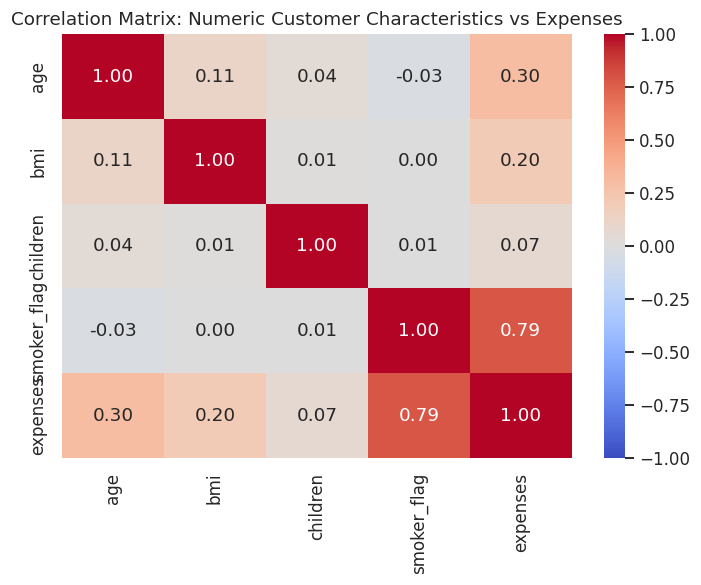

In [14]:
num_cols = ["age", "bmi", "children", "smoker_flag", "expenses"]
corr = df_clean[num_cols].corr()

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix: Numeric Customer Characteristics vs Expenses")
plt.show()

corr["expenses"].sort_values(ascending=False)


**Q1. What does the overall distribution of expenses look like and how strongly is
each numeric characteristic correlated with it?** Smoking status shows by far the
strongest linear association with expenses (r ≈ 0.79) followed by age (r ≈ 0.30) and
BMI (r ≈ 0.20). Number of children shows almost no linear relationship with expenses
(r ≈ 0.07).

Mean:    $13,279.12
Median:  $9,386.16
Skewness: 1.52


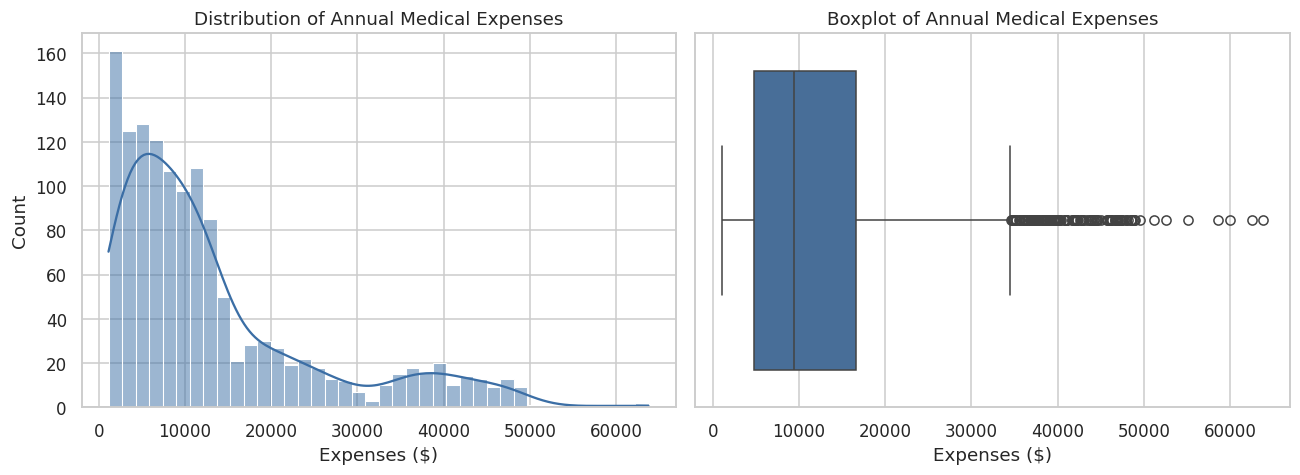

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df_clean["expenses"], bins=40, kde=True, ax=axes[0], color="#3b6ea5")
axes[0].set_title("Distribution of Annual Medical Expenses")
axes[0].set_xlabel("Expenses ($)")

sns.boxplot(x=df_clean["expenses"], ax=axes[1], color="#3b6ea5")
axes[1].set_title("Boxplot of Annual Medical Expenses")
axes[1].set_xlabel("Expenses ($)")
plt.show()

print(f"Mean: ${df_clean['expenses'].mean():,.2f}")
print(f"Median: ${df_clean['expenses'].median():,.2f}")
print(f"Skew: {df_clean['expenses'].skew():.2f}")


            mean    median       std  count
smoker                                     
no      8,440.66  7,345.73  5,992.97   1063
yes    32,050.23 34,456.35 11,541.55    274

Welch's t-test: t = 32.74, p = 6.26e-103


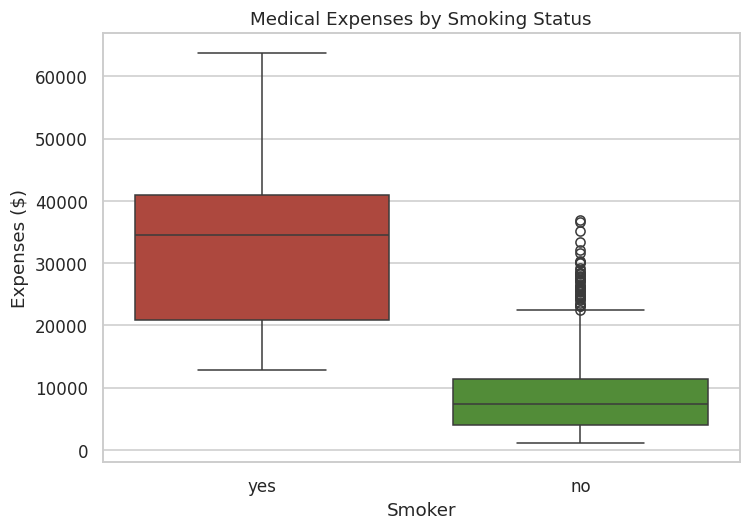

In [16]:
smoker_stats = df_clean.groupby("smoker")["expenses"].agg(["mean", "median", "std", "count"])
print(smoker_stats.round(2))

group_smoker = df_clean.loc[df_clean.smoker == "yes", "expenses"]
group_nonsmoker = df_clean.loc[df_clean.smoker == "no", "expenses"]
t_stat, p_val = stats.ttest_ind(group_smoker, group_nonsmoker, equal_var=False)
print(f"\nWelch t: t={t_stat:.2f}, p={p_val:.2e}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df_clean, x="smoker", y="expenses", hue="smoker",
            palette={"no": "#4c9a2a", "yes": "#c0392b"}, legend=False)
plt.title("Medical Expenses by Smoking Status")
plt.xlabel("Smoker"); plt.ylabel("Expenses ($)")
plt.show()


**Finding:** Smokers incur dramatically higher expenses than non-smokers (mean ≈
32,050 vs 8,434), and this difference is statistically significant (p < 0.001).
Smoking status is the single strongest driver of expenses identified in this dataset.

Smoker=yes: Pearson r = 0.81, p = 0.0000
Smoker=no : Pearson r = 0.08, p = 0.0062


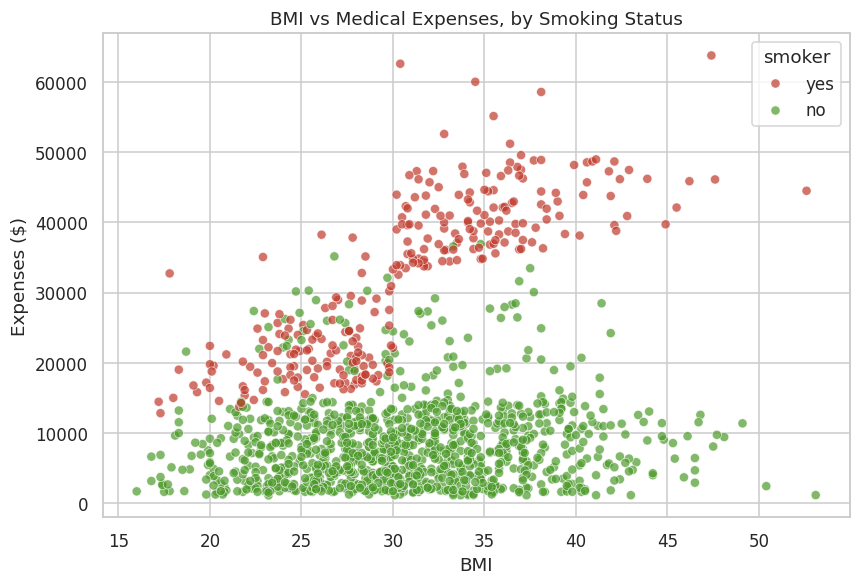

In [17]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df_clean, x="bmi", y="expenses", hue="smoker",
                 palette={"no": "#4c9a2a", "yes": "#c0392b"}, alpha=0.7)
plt.title("BMI vs Medical Expenses, by Smoking Status")
plt.xlabel("BMI"); plt.ylabel("Expenses ($)")
plt.show()

for grp in ["yes", "no"]:
    sub = df_clean[df_clean.smoker == grp]
    r, p = stats.pearsonr(sub["bmi"], sub["expenses"])
    print(f"Smoker={grp:3s}: Pearson r = {r:.2f}, p = {p:.4f}")


**Finding:** BMI is weakly correlated with expenses among non-smokers (r ≈ 0.08, not significant) but strongly correlated among smokers (r ≈ 0.81, p < 0.001). This suggests an interaction effect where high BMI is particularly costly among smokers.

Overall Pearson r (age vs expenses) = 0.30, p = 6.98e-29


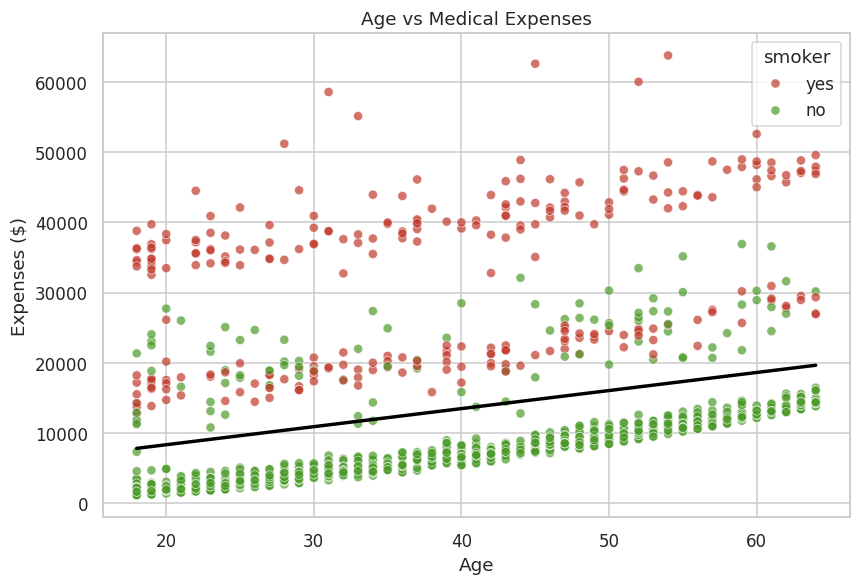

In [18]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df_clean, x="age", y="expenses", hue="smoker",
                 palette={"no": "#4c9a2a", "yes": "#c0392b"}, alpha=0.7)
sns.regplot(data=df_clean, x="age", y="expenses", scatter=False, color="black", ci=None)
plt.title("Age vs Medical Expenses")
plt.xlabel("Age"); plt.ylabel("Expenses ($)")
plt.show()

r, p = stats.pearsonr(df_clean["age"], df_clean["expenses"])
print(f"Overall Pearson r (age vs expenses) = {r:.2f}, p = {p:.2e}")


**Finding:** Expenses rise steadily with age (r ≈ 0.30, p < 0.001), consistent with
the expected increase in healthcare utilisation with age. Three visually distinct
upward bands are apparent in the scatterplot, driven primarily by smoking status and
within smokers by BMI.

               mean    median  count
region                              
northeast 13,406.38 10,057.65    324
northwest 12,450.84  8,976.98    324
southeast 14,735.41  9,294.13    364
southwest 12,346.94  8,798.59    325

One-way ANOVA: F = 2.93, p = 0.0328


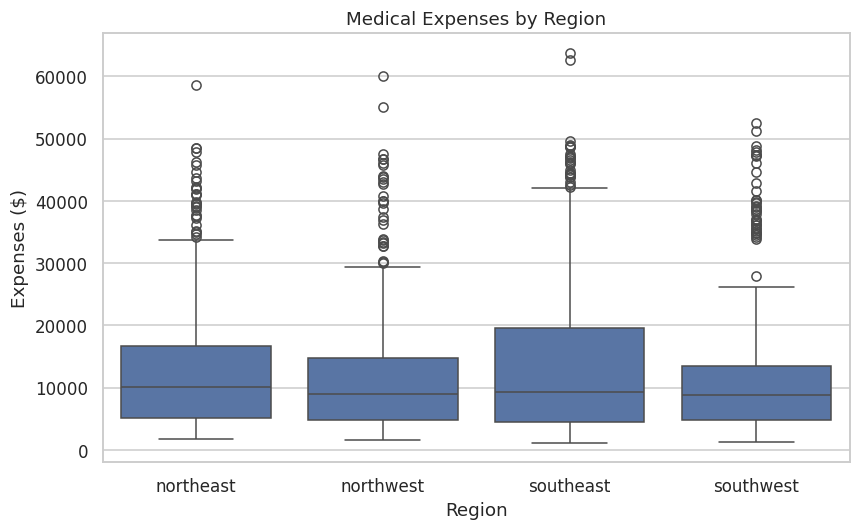

In [19]:
region_stats = df_clean.groupby("region")["expenses"].agg(["mean", "median", "count"]).round(2)
print(region_stats)

groups = [df_clean.loc[df_clean.region == r, "expenses"] for r in df_clean.region.unique()]
f_stat, p_val = stats.f_oneway(*groups)
print(f"\nOne-way ANOVA: F = {f_stat:.2f}, p = {p_val:.4f}")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="region", y="expenses", order=sorted(df_clean.region.unique()))
plt.title("Medical Expenses by Region")
plt.xlabel("Region"); plt.ylabel("Expenses ($)")
plt.show()


**Finding:** Mean expenses range from 12,347 in the southwest to 14,735 in the southeast. ANOVA shows this difference is statistically significant (F = 2.93, p = .033) but the effect is small compared with smoking or age. The higher southeast mean may partly reflect its higher proportion of smokers.

              mean    median  count
children                           
0        12,384.70  9,863.47    573
1        12,731.17  8,483.87    324
2        15,073.56  9,264.98    240
3        15,355.32 10,600.55    157
4        13,850.66 11,033.66     25
5         8,786.04  8,589.56     18
Pearson r (children vs expenses) = 0.07, p = 0.0137


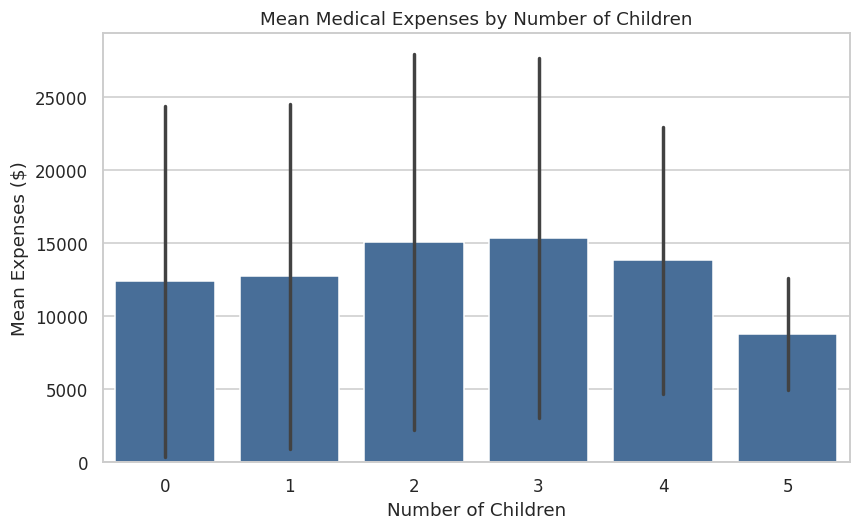

In [20]:
children_stats = df_clean.groupby("children")["expenses"].agg(["mean", "median", "count"]).round(2)
print(children_stats)

plt.figure(figsize=(8, 5))
sns.barplot(data=df_clean, x="children", y="expenses", errorbar="sd", color="#3b6ea5")
plt.title("Mean Medical Expenses by Number of Children")
plt.xlabel("Number of Children"); plt.ylabel("Mean Expenses ($)")
plt.show()

r, p = stats.pearsonr(df_clean["children"], df_clean["expenses"])
print(f"Pearson r (children vs expenses) = {r:.2f}, p = {p:.4f}")


**Finding:** Number of children shows no meaningful linear relationship with expenses
(r ≈ 0.07). Mean expenses are broadly similar across 0–4 children, with the 5-children
group differing but represented by a very small subsample.

            mean   median  count
sex                             
female 12,569.58 9,412.96    662
male   13,975.00 9,377.90    675

Welch's t-test: t = 2.13, p = 0.0336


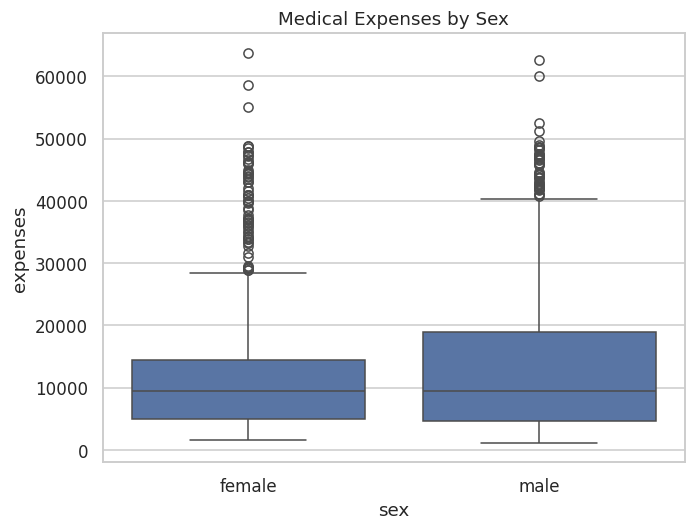

In [21]:
sex_stats = df_clean.groupby("sex")["expenses"].agg(["mean", "median", "count"]).round(2)
print(sex_stats)

t_stat, p_val = stats.ttest_ind(
    df_clean.loc[df_clean.sex == "male", "expenses"],
    df_clean.loc[df_clean.sex == "female", "expenses"],
    equal_var=False,
)
print(f"\nWelch t: t={t_stat:.2f}, p={p_val:.4f}")

plt.figure(figsize=(6.5, 5))
sns.boxplot(data=df_clean, x="sex", y="expenses")
plt.title("Medical Expenses by Sex")
plt.show()


**Finding:** Mean expenses is modestly higher for males than females (13,975 vs
12,570), and this difference is statistically significant at α = 0.05 (p = .034).
The effect size is small relative to smoking and age but sex should not be dismissed
as a factor without further multivariate investigation.

smoker             no       yes
bmi_category                   
Underweight  5,533.00 18,810.00
Normal       7,600.00 19,942.00
Overweight   8,299.00 22,496.00
Obese        8,856.00 41,558.00


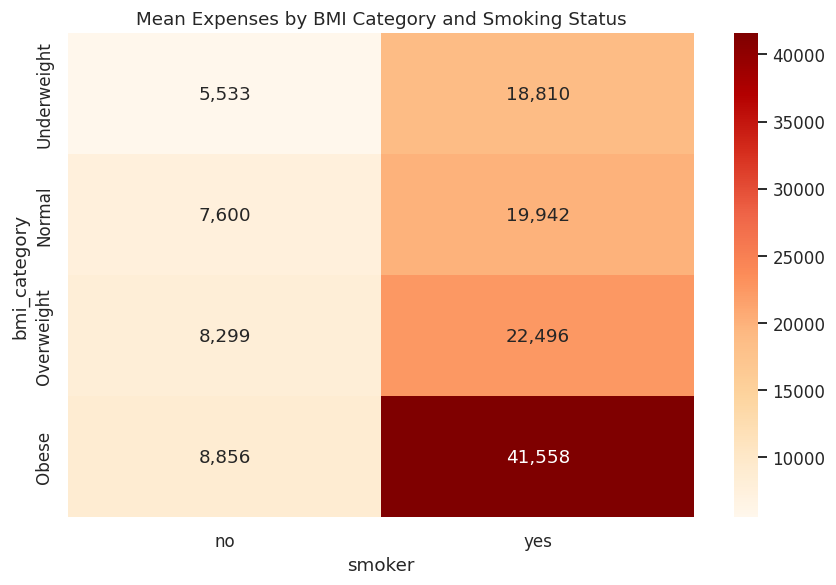

In [22]:
pivot = df_clean.pivot_table(values="expenses", index="bmi_category",
                              columns="smoker", aggfunc="mean").round(0)
print(pivot)

plt.figure(figsize=(8, 5.5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="OrRd")
plt.title("Mean Expenses by BMI Category and Smoking Status")
plt.show()


**Finding:** The highest cost segment by a wide margin is obese smokers
(mean expenses roughly 4–5x higher than the obese non-smokers) confirming the interaction
identified in Q3: smoking and obesity combine to produce the highest risk, highest cost
customer profile in the portfolio.

## 6. Summary of Business Questions Answered

In [23]:
summary = pd.DataFrame([
    ["Q1: Expenses distribution?", "Right-skewed; mean > median", "Descriptive stats", "-"],
    ["Q2: Smoking affect expenses?", "Smokers pay ~3.8x more", "Welch t-test", "p < 0.001"],
    ["Q3: BMI affect expenses?", "Weak for non-smokers (r=.08); strong for smokers (r=.81)", "Pearson corr", "p < 0.001"],
    ["Q4: Age affect expenses?", "Expenses rise steadily with age", "Pearson corr", "p < 0.001"],
    ["Q5: Region affect expenses?", "Small diff (southeast highest)", "ANOVA", "p = .0328*"],
    ["Q6: Children affect expenses?", "Significant but very weak (r=.07)", "Pearson corr", "p = .0137*"],
    ["Q7: Sex affect expenses?", "Small (men slightly higher)", "Welch t-test", "p = .0336*"],
    ["Q8: Highest-cost segment?", "Obese smokers, by far", "Pivot table", "-"],
], columns=["Business Question", "Key Finding", "Method", "p-value"])
summary


,Business Question,Key Finding,Method,p-value
0,Q1: What does the expenses distribution look like?,"Right-skewed; mean $13,270 > median $9,382",Descriptive stats,-
1,Q2: Does smoking status affect expenses?,Yes - smokers pay ~3.8x more on average,Welch t-test,p < 0.001
2,"Q3: Does BMI affect expenses, and does smoking change this?",Weak for non-smokers (r=.08); strong for smokers (r=.81),Pearson correlation,p < 0.001 (smokers)
3,Q4: Does age affect expenses?,Yes - expenses rise steadily with age,Pearson correlation,p < 0.001
4,Q5: Does region affect expenses?,Small but statistically significant difference (southeast highest),One-way ANOVA,p = .0328*
5,Q6: Does number of children affect expenses?,Statistically significant but practically very weak (r=.07),Pearson correlation,p = .0137*
6,Q7: Does sex affect expenses?,Small but statistically significant (men slightly higher),Welch t-test,p = .0336*
7,Q8: Which segment is highest-risk/highest-cost?,Obese smokers - by far the highest mean expenses,Pivot table,-


*Note: for Q5–Q7 have p-values below .05 their practical effects are small. Sex and region explain only modest differences in mean expenses while children has a weak correlation (r = .07). With a large sample (N = 1,337) even small effects can be statistically significant. Therefore, statistical and business significance are interpreted separately.*

## 7. A Simple Predictive Model 
This section demonstrates how the same customer characteristics can predict expenses for a customer. It compares two approaches: a transparent linear regression (highly interpretable for underwriters) and a random forest (typically more accurate but less transparent), building on the EDA insights rather than replacing them.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

features = ["age", "bmi", "children", "sex", "smoker", "region"]
X = df_clean[features]
y = df_clean["expenses"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

categorical = ["sex", "smoker", "region"]
numeric = ["age", "bmi", "children"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first"), categorical),
], remainder="passthrough")

print(f"Training rows: {len(X_train)}  |  Test rows: {len(X_test)}")


Training rows: 1069  |  Test rows: 268


In [25]:
lin_pipe = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
lin_pipe.fit(X_train, y_train)
pred_lin = lin_pipe.predict(X_test)

print("Linear Regression performance (test set):")
print(f"  R^2  = {r2_score(y_test, pred_lin):.3f}")
print(f"  MAE  = ${mean_absolute_error(y_test, pred_lin):,.2f}")
print(f"  RMSE = ${mean_squared_error(y_test, pred_lin) ** 0.5:,.2f}")


Linear Regression performance (test set):
  R^2  = 0.807
  MAE  = $4,177.27
  RMSE = $5,956.63


In [26]:
rf_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestRegressor(
    n_estimators=300, max_depth=6, random_state=42))])
rf_pipe.fit(X_train, y_train)
pred_rf = rf_pipe.predict(X_test)

print("Random Forest performance (test set):")
print(f"  R^2  = {r2_score(y_test, pred_rf):.3f}")
print(f"  MAE  = ${mean_absolute_error(y_test, pred_rf):,.2f}")
print(f"  RMSE = ${mean_squared_error(y_test, pred_rf) ** 0.5:,.2f}")


Random Forest performance (test set):
  R^2  = 0.898
  MAE  = $2,464.10
  RMSE = $4,321.62



Linear model coefficients (impact on predicted expenses, $ per unit):
cat__region_southeast     -840.05
cat__region_southwest     -658.71
cat__region_northwest     -391.94
cat__sex_male             -101.76
remainder__age             248.18
remainder__bmi             318.94
remainder__children        533.35
cat__smoker_yes         23,076.98
dtype: float64


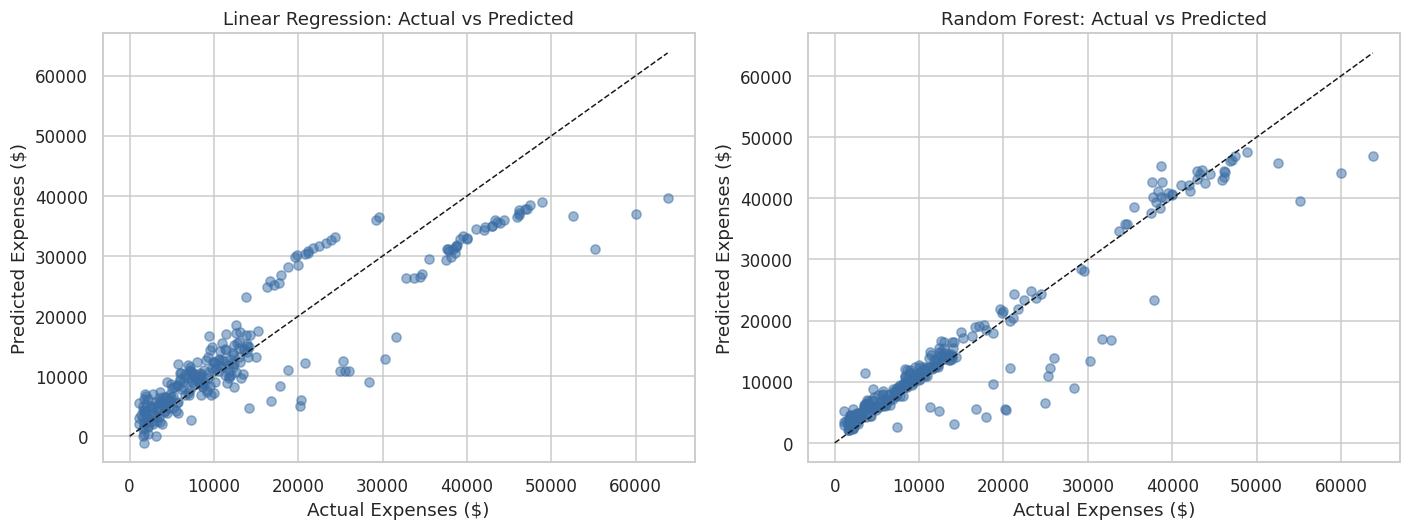

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pred, title in zip(axes, [pred_lin, pred_rf], ["Linear Regression", "Random Forest"]):
    ax.scatter(y_test, pred, alpha=0.5, color="#3b6ea5")
    lims = [0, max(y_test.max(), pred.max())]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_xlabel("Actual Expenses ($)"); ax.set_ylabel("Predicted Expenses ($)")
    ax.set_title(f"{title}: Actual vs Predicted")
plt.show()

feat_names = lin_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lin_pipe.named_steps["model"].coef_, index=feat_names).sort_values()
print("\nLinear model coefficients ($ per unit):")
print(coefs.round(2))


**Model findings:** The random forest outperforms the linear model (R² = 0.898 vs. 0.807; MAE ≈ 2,464 vs. 4,177), capturing non-linear effects such as smoking × BMI. In the linear model, smoking has the largest effect 23,077 followed by children 533 per child, BMI 319 per unit and age 248 per year. Sex and region have smaller effects all below 850 indicating limited practical impact.

## 8. Key Insights and Recommendations for HealthSure Insurance

### 8.1 Key Insights
- Smoking is the dominant cost driver — smokers incur about 3.8× higher expenses than non-smokers 32,050 vs. 8,441; p < .001).
- Smoking and BMI interact strongly — BMI has little relationship with costs among non-smokers (r = .08) but a strong relationship among smokers (r = .81). Smokers with high BMI are the highest cost group.
- Age has a moderate effect — expenses increase with age (r = .30, p < .001).
- Region, sex and children have smaller effects — although statistically significant their practical impact is modest compared with smoking, BMI and age.
- The model predicts well — the random forest explains about 90% of expense variation (R² = 0.898), showing that the six predictors jointly provide strong predictive power.

### 8.2 Recommendations
- Risk-based pricing - Prioritize smoking and BMI with age as a secondary factor.
- High-risk segmentation - Identify obese smokers for targeted risk management and wellness programs.
- Wellness programs - Combine smoking cessation with weight management for this high cost group.
- Deprioritize region and sex - Their small effects provide limited value for pricing decisions.
- Use the model - Pilot the random forest (R² = 0.898) as decision-support for identifying high cost customers.

## 9. Limitations
- Missing likely cost drivers (pre-existing conditions, family history, occupation, claims history), so R² is an upper bound on these six variables alone.
- Region is a coarse 4-category grouping that may hide finer geographic variation.
- The random forest wasn't extensively tuned  treat as an illustrative baseline, not production-ready, pending cross-validation.
  
## 10. Conclusion
The analysis addressed the objectives set out in the business context.The analysis found that smoking
status, BMI particularly in combination with smoking and age are the primary drivers
of medical insurance expenses in HealthSure's customer base while region, sex and
number of children play comparatively minor roles. A supplementary predictive model
demonstrated that these characteristics can jointly explain close to 90%
of the variance in customer expenses, supporting their use in future pricing and risk
management applications.

## 11. References

Mahdavi, M. (n.d.) *insurance.csv*, in *teaching* [GitHub repository]. Available at:
https://github.com/m-mahdavi/teaching/blob/main/datasets/insurance.csv.

Harris, C.R., Millman, K.J., van der Walt, S.J., et al. (2020) 'Array programming with
NumPy', *Nature*, 585, pp. 357–362.

Hunter, J.D. (2007) 'Matplotlib: A 2D graphics environment', *Computing in Science &
Engineering*, 9(3), pp. 90–95.

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011) 'Scikit-learn: Machine
learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830.

World Health Organization (2000) *Obesity: preventing and managing the global
epidemic: report of a WHO consultation*. Geneva: World Health Organization. 